# NB 3: Druk, temperatuur en energie



In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

BOX_SIZE_0 = 10                # Hoogte en lengte startvolume
N = 40                         # Aantal deeltjes
V_0 = 1                        # Startsnelheid van deeltjes
RADIUS = 0.3                   # Straal van moleculen
DT = 0.1 * RADIUS / V_0        # Tijdstap om geen botsing te missen

De klasse voor de gasmoleculen en de functies voor hun onderlinge interactie:



In [6]:
class ParticleClass:
    def __init__(self, m, v, r, R):
        """ maakt een deeltje (constructor) """
        self.m = m                         
        self.v = np.array(v, dtype=float)  
        self.r = np.array(r, dtype=float)  
        self.R = R

    def update_position(self):
        """ verandert positie voor één tijdstap """
        self.r += self.v * DT 
            
    @property
    def momentum(self):
        return self.m * self.v
    
    @property
    def kin_energy(self):
        return 1/2 * self.m * np.dot(self.v, self.v)
    
def collide_detection(p1: ParticleClass, p2: ParticleClass) -> bool:
    """ Geeft TRUE als de deeltjes overlappen """
    dx = p1.r[0] - p2.r[0]
    dy = p1.r[1] - p2.r[1]
    rr = p1.R + p2.R
    return  dx**2+dy**2 < rr**2 

def particle_collision(p1: ParticleClass, p2: ParticleClass):
    """ past snelheden aan uitgaande van overlap """
    m1, m2 = p1.m, p2.m
    delta_r = p1.r - p2.r
    delta_v = p1.v - p2.v
    dot_product = np.dot(delta_r, delta_v)

    # Als deeltjes van elkaar weg bewegen dan geen botsing
    if dot_product >= 0: # '='-teken voorkomt ook problemen als delta_r == \vec{0}
        return

    distance_squared = np.dot(delta_r, delta_r) 
    # Botsing oplossen volgens elastische botsing in 2D
    p1.v -= 2 * m2 / (m1 + m2) * dot_product / distance_squared * delta_r
    p2.v += 2 * m1 / (m1 + m2) * dot_product / distance_squared * delta_r

Het volume met de ‘oude’ randvoorwaarden. Dit zijn niet de randvoorwaarden van het vorige werkblad, maar de randvoorwaarden die je eerder hebt gebruikt. Hierbij botsen de deeltjes elastisch met de wanden van het volume.



In [11]:
def box_collision(particle: ParticleClass):
    ''' botsing met harde wanden '''
    if abs(particle.r[0]) + particle.R > BOX_SIZE_0/2: 
        particle.v[0] = -particle.v[0]                                        # Omdraaien van de snelheid
        particle.r[0] = np.sign(particle.r[0]) * (BOX_SIZE_0/2 - particle.R)  # Zet terug net binnen box                 
    if abs(particle.r[1]) + particle.R > BOX_SIZE_0/2: 
        particle.v[1] = -particle.v[1]     
        particle.r[1] = np.sign(particle.r[1]) * (BOX_SIZE_0/2 - particle.R) 

Het uitvoeren en samennemen van deze functies over een lijst met deeltjes:



In [8]:
def create_particles(particles):
    """ Leegmaken en opnieuw aanmaken van deeltjes  in lijst """
    particles.clear()
    for i in range(N):
        vx = np.random.uniform(-V_0, V_0)
        vy = np.random.choice([-1, 1]) * np.sqrt(V_0**2 - vx**2)        
        pos = np.random.uniform(-BOX_SIZE_0/2 + RADIUS, BOX_SIZE_0/2 - RADIUS, 2)
        particles.append(ParticleClass(m=1.0, v=[vx, vy], r=pos, R=RADIUS))

# note dat deze handle_collisions functie anders is dan we gedaan in brownian motion
# controleer zelf welke van de twee functies sneller is (wat, zoals gezegd, sterk afhangt van het aantal deeltjes!)
def handle_collisions(particles):
    """ alle onderlinge botsingen afhandelen voor deeltjes in lijst """
    num_particles = len(particles)
    for i in range(num_particles):
        for j in range(i+1, num_particles):
            if collide_detection(particles[i], particles[j]):
                particle_collision(particles[i], particles[j])

def handle_walls(particles):
    """ botsing met wanden controleren voor alle deeltjes in lijst """
    for p in particles:
        box_collision(p)

# de eigenlijke stappen in de simulatie
def take_time_step(particles):
    """ zet tijdstap voor een lijst deeltjes en verwerk alle botsingen onderling en met wanden """
    for p in particles:
        p.update_position()
    handle_collisions(particles)
    handle_walls(particles)  


Laten we controleren of de deeltjes gemaakt zijn en of ze allemaal een snelheid hebben:



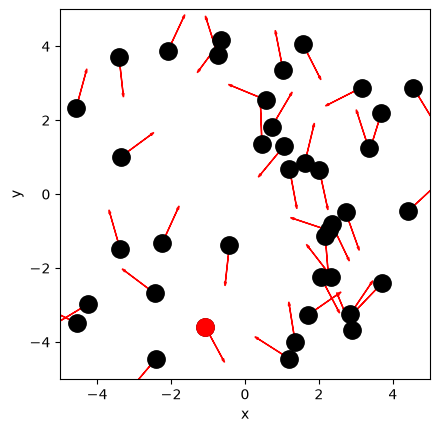

In [9]:
particles = []
create_particles(particles)

plt.figure()
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('equal')
plt.xlim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
plt.ylim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
for p in particles:
    plt.plot(p.r[0], p.r[1], 'k.', ms=25)
    plt.arrow(p.r[0], p.r[1], p.v[0], p.v[1], 
              head_width=0.05, head_length=0.1, color='red')
plt.plot(particles[0].r[0],particles[0].r[1], 'r.', ms=25)
plt.show()

## Het draaien van een eerste simulatie ter controle 

Laten we het eerst zo eenvoudig mogelijk maken en controleren of het lukt om honderd tijdstappen te zetten met de hierboven gedefinieerde functies. Als resultaat beperken we ons tot het plotten van de posities van de deeltjes en hun snelheden.



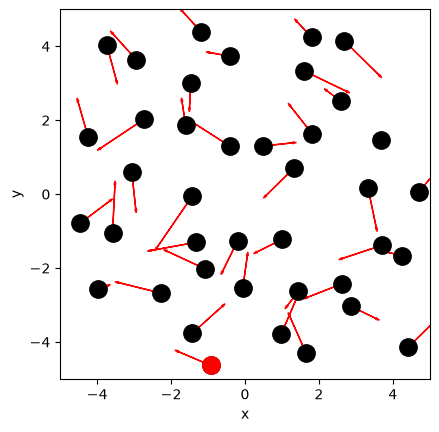

In [12]:

# doorlopen van de simulatie
for i in range(100):
    take_time_step(particles)

# plotten van de positie van de deeltjes en hun snelheid als vector
plt.figure()
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('equal')
plt.xlim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
plt.ylim(-BOX_SIZE_0/2, BOX_SIZE_0/2)

for p in particles:
    plt.plot(p.r[0], p.r[1], 'k.', ms=25)
    plt.arrow(p.r[0], p.r[1], p.v[0], p.v[1], 
              head_width=0.05, head_length=0.1, color='red')
plt.plot(particles[0].r[0],particles[0].r[1], 'r.', ms=25)
plt.show()

### Ex. 1: Temperatuurfunctie

Schrijf een functie die de temperatuur van het gas in onze simulatie bepaalt:

$\frac{f}{2}kT = \frac{1}{2}mv^2$

$T = \frac{mv^2}{fk} $

In [30]:
k = 1.380649e-23 #constante van Boltzmann
f = 2 #aantal dimensies

def temperature(particles) -> float:
    temp = 0.0 
    ### YOUR CODE HERE ###
    for p in particles:
        temp += ( p.m * np.sqrt(p.v[0]**2 + p.v[1]**2)**2 ) / ( f * k )

    temp = temp / N #gemiddelde temp van het aantal deeltjes
    return temp

print (f"Temperatuur van het gas is {temperature(particles)} K.")


Temperatuur van het gas is 3.621485258019959e+22 K.


De temperatuur komt nu uit op een gigantische waarde, maar dat komt omdat massa nog niet is gedefinieerd. Zie hieronder toetsing met $H_2O$ (deeltje met een massawaarde in de ordergrootte van $10^{-26}$ kg )


In [46]:
m_water = 18.01528e-3 / 6.02214e23 #kg per mol / het getal van avogadro
print(f"De temperatuur van waterdamp middels de bovenstaande formule is {((m_water * (640.0)**2 ) / ( f * k ))-273:.2f} graden Celsius. Deze waarde is realistisch.")


De temperatuur van waterdamp middels de bovenstaande formule is 170.75 graden Celsius. Deze waarde is realistisch.


### Exercise 2 (temperatuurplot)

Gebruik deze functie om een simulatie te maken waarin je de temperatuur als functie van de tijdstap voor 100 tijdstappen plot.




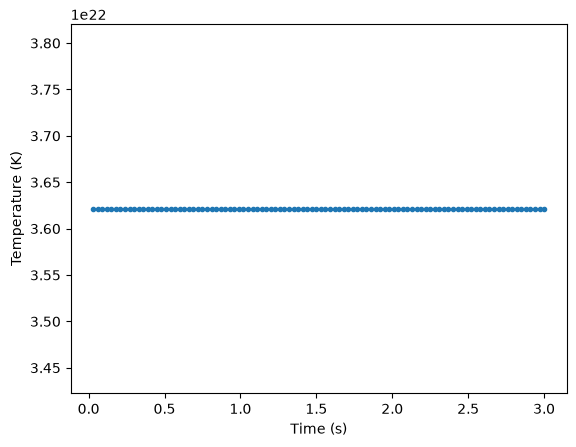

In [53]:
# ruimte voor uitwerking

particles = []
temperatures = np.zeros(100, dtype=float)
times = np.linspace(1, 100, 100)*DT

create_particles(particles)
for i in range(100):
    take_time_step(particles)
    # vastleggen van temperatuur per tijdstap
    ### YOUR CODE HERE ###
    temperatures[i] = temperature(particles)

plt.figure()
plt.xlabel('Time (s)')
plt.ylabel('Temperature (K)')
# plotten van tijd tegen temperatuur
### YOUR CODE HERE ###
plt.plot(times,temperatures, '.')
plt.show()


De temperatuur is hier vrij hoog, maar dat is hierboven verklaard. Geen verandering omdat dit niet is gedefinieerd. 

### Exercise 3: assen 
Code hierboven aangepast. We berekenen tijd als volgt: 

$tijd (s) = tijdstap \cdot DT$